# Multinomial Logistic Regression (Softmax Regression) on the Iris Dataset

This notebook builds a **multiclass classifier** for the three Iris species and explains the complete prediction process:

$$
\text{input features}
\rightarrow \text{class logits}
\rightarrow \text{Softmax probabilities}
\rightarrow \operatorname{argmax}
\rightarrow \text{predicted class}
$$

## Learning Objectives

By the end of this notebook, you will be able to:

- prepare a dataset for multiclass classification;
- train a **Multinomial Logistic Regression** model;
- interpret the learned weights and biases;
- calculate logits and Softmax probabilities manually;
- evaluate predictions with accuracy, cross-entropy, a classification report, and a confusion matrix;
- visualize multiclass decision regions; and
- compare a two-feature visualization model with a model that uses all four Iris features.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    log_loss,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler

sns.set_theme(style="whitegrid")

## 1. Load and Explore the Iris Dataset

The Iris dataset contains **150 raw flower samples** (149 after removing one duplicate), four numerical input features, and three mutually exclusive species. Each species is one possible class.

In [2]:
raw_df = sns.load_dataset("iris")
raw_df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
print(f"Dataset shape before deduplication: {raw_df.shape}")
print(f"Duplicate rows: {raw_df.duplicated().sum()}")
raw_df = raw_df.drop_duplicates().reset_index(drop=True)
print(f"Dataset shape after deduplication: {raw_df.shape}")

print("\nMissing values per column:")
display(raw_df.isna().sum().to_frame("missing_values"))

print("Class distribution:")
display(raw_df["species"].value_counts().sort_index().to_frame("samples"))

print("Numerical summary:")
display(raw_df.describe().round(2))

Dataset shape before deduplication: (150, 5)
Duplicate rows: 1
Dataset shape after deduplication: (149, 5)

Missing values per column:


,missing_values
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species,0


Class distribution:


,samples
species,
setosa,50
versicolor,50
virginica,49


Numerical summary:


,sepal_length,sepal_width,petal_length,petal_width
count,149.00,149.00,149.00,149.00
mean,5.84,3.06,3.75,1.19
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.30,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


### Pairplot: All Features vs All Features

The pairplot below shows every pair of the four measurements. Each point is one flower, coloured by species.

**What to look for:**
- **Diagonal** (KDE curves) — the distribution of each feature per class; narrow, separated peaks mean the feature discriminates well.
- **Off-diagonal** (scatter plots) — if two species form distinct clusters, those two features together provide a clean decision boundary.
- **Overlap** — Versicolor and Virginica share similar sepal measurements; the petal features separate them much more clearly, which motivates our feature selection in the next section.

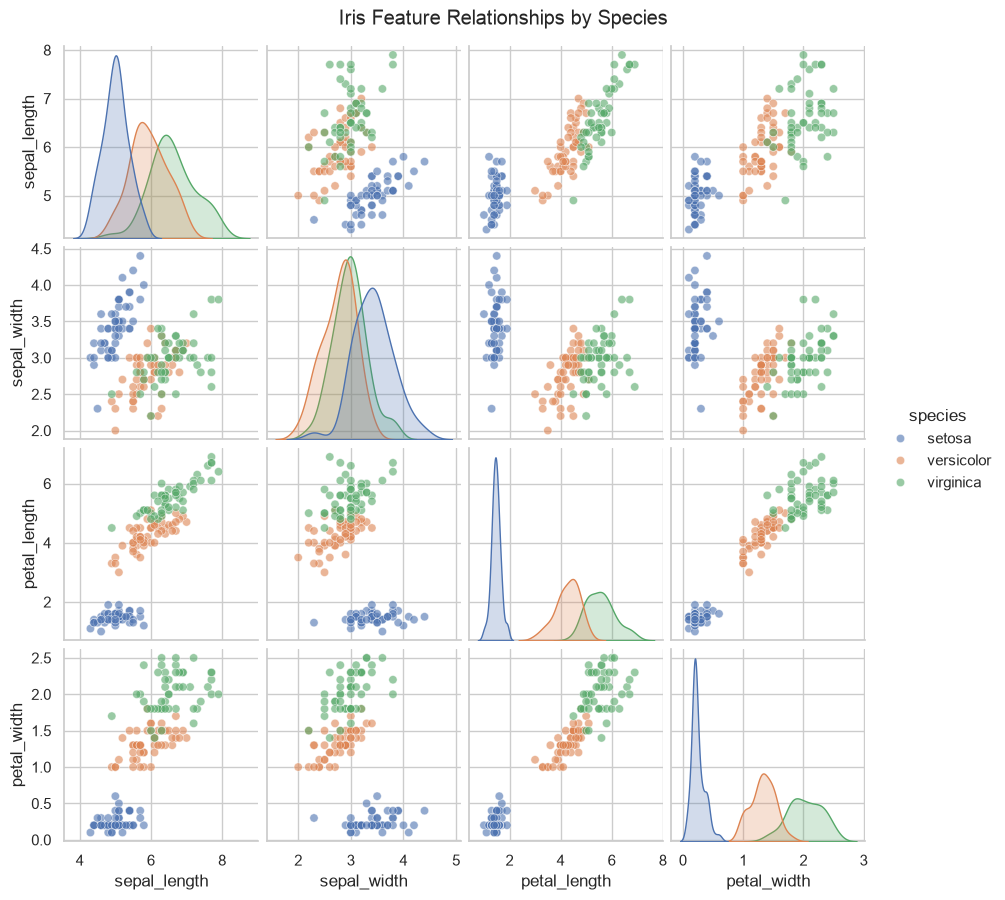

In [4]:
sns.pairplot(raw_df, hue="species", diag_kind="kde", plot_kws={"alpha": 0.6}, height=2.2)
plt.suptitle("Iris Feature Relationships by Species", y=1.02)
plt.show()

## 2. Encode the Target Classes

`LabelEncoder` converts the species names into **integer class labels**. Scikit-learn can also train directly with string labels, but integer labels make the class indices easier to connect to the mathematical notation.

| Species | Label-encoded target | Equivalent one-hot target |
|---|---:|---|
| Setosa | `0` | `[1, 0, 0]` |
| Versicolor | `1` | `[0, 1, 0]` |
| Virginica | `2` | `[0, 0, 1]` |

The notebook uses **label encoding**, not one-hot encoding. Both representations identify the same correct class; for example, label `1` and one-hot vector `[0, 1, 0]` both mean **Versicolor**.

Scikit-learn's `LogisticRegression.fit()` expects the target `y` as a **one-dimensional vector of class labels**, so `0`, `1`, and `2` are sufficient. Internally, the multinomial loss selects the predicted probability for the correct class, which is mathematically equivalent to using a one-hot target in the categorical cross-entropy formula. We may construct one-hot targets to demonstrate that formula, but we should not pass a one-hot target matrix to this `LogisticRegression` model because it can represent a different multi-output or multilabel problem.

> [!NOTE]
> The integer labels do **not** create an order between the species. The values `0`, `1`, and `2` are identifiers only; class `2` is not greater or more important than class `1`.

In [5]:
encoder = LabelEncoder()
df = raw_df.copy()
df["species"] = encoder.fit_transform(df["species"])

class_mapping = dict(zip(encoder.classes_, encoder.transform(encoder.classes_)))
print("Class mapping:", class_mapping)
df.head()

Class mapping: {'setosa': np.int64(0), 'versicolor': np.int64(1), 'virginica': np.int64(2)}


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


## 3. Select and Visualize Two Features

The first model uses only **sepal length** and **petal length** so that its decision regions can be plotted in two dimensions. A later model uses all four features.

- $X$ contains the input features.
- $y$ contains the encoded target class.

In [6]:
feature_names = ["sepal_length", "petal_length"]
X = df[feature_names]
y = df["species"]

### 2D Feature Space: Sepal Length vs Petal Length

Reducing to two features lets us visualise the decision boundary as a 2D region. The scatter plot shows:

- **Setosa** (bottom-left) — naturally separated from the other two by both measurements.
- **Versicolor / Virginica** (upper-right) — partially overlapping; a linear boundary cannot perfectly separate them using only these two features.

This overlap is the reason that the model trained on just two features achieves lower accuracy than the all-features model in Section 10.

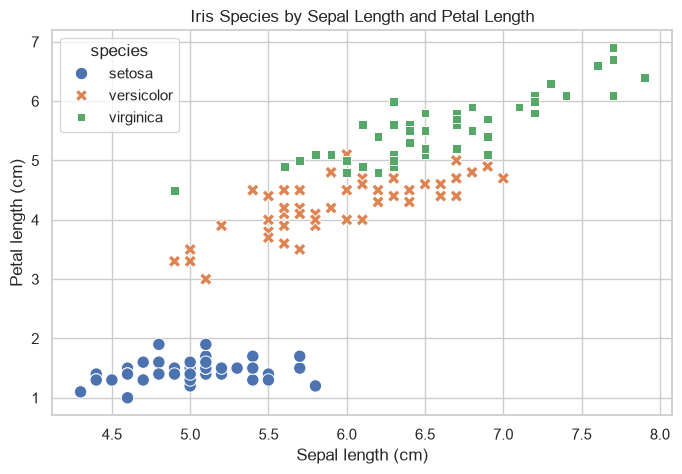

In [7]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=raw_df,
    x="sepal_length",
    y="petal_length",
    hue="species",
    style="species",
    s=80,
)
plt.title("Iris Species by Sepal Length and Petal Length")
plt.xlabel("Sepal length (cm)")
plt.ylabel("Petal length (cm)")
plt.show()

## 4. Create Stratified Training and Test Sets

- `test_size=0.2` reserves 20% of the data for evaluation.
- `random_state=2` makes the split reproducible.
- `stratify=y` preserves the class proportions in both subsets.

The test data must remain unseen during training so that it measures how well the model generalizes.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=2,
    stratify=y,
)

split_summary = pd.DataFrame(
    {
        "training_samples": y_train.value_counts().sort_index(),
        "test_samples": y_test.value_counts().sort_index(),
    }
).rename(index=dict(enumerate(encoder.classes_)))

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
display(split_summary)

X_train shape: (119, 2)
X_test shape: (30, 2)


,training_samples,test_samples
species,,
setosa,40,10
versicolor,40,10
virginica,39,10


## 5. Train the Multinomial Logistic Regression Model

`lbfgs` optimizes the model's categorical cross-entropy objective. With three classes, current scikit-learn versions fit the full **multinomial** model automatically.

For every class $k$, the model learns a weight vector $\mathbf{w}_k$ and bias $b_k$:

$$
z_k = \mathbf{w}_k^\top\mathbf{x} + b_k
$$

**`max_iter=500`** sets the maximum number of optimisation iterations. If the solver has not converged by this limit it stops early and scikit-learn raises a `ConvergenceWarning`. The default of 100 is often too low for scaled or complex datasets; 500 gives sufficient room to converge cleanly.

**Multinomial vs One-vs-Rest (OvR)**

`lbfgs` uses the **multinomial** (Softmax) formulation — a single model trained jointly across all classes at once. The alternative, **One-vs-Rest**, trains one binary classifier per class and picks the most confident one.

| | Multinomial (Softmax) | One-vs-Rest |
|---|---|---|
| Number of models | 1 joint model | $K$ separate binary models |
| Probabilities | Always sum to 1 | No guarantee |
| Better when | Classes overlap | Classes are well-separated |
| Default for `lbfgs` | ✓ Yes | ✗ No |

`LogisticRegression` also applies L2 regularization by default. Its `C` parameter controls the inverse regularization strength.

In [9]:
softmax_model = LogisticRegression(solver="lbfgs", max_iter=500)
softmax_model.fit(X_train, y_train)

softmax_classes = encoder.inverse_transform(softmax_model.classes_)
print("Encoded classes:", softmax_model.classes_)
print("Species order:", softmax_classes)

Encoded classes: [0 1 2]
Species order: ['setosa' 'versicolor' 'virginica']


### Where Do W and b Come From?

$W$ and $\mathbf{b}$ are **learned during training** by the `lbfgs` optimizer. Each iteration runs a full cycle:

> **Forward pass** → **Compute loss** → **Backward pass** → **Update parameters**

---

#### Step 1 — Initialise W and b (once, before training)

- $W$ is filled with small **random values** — one row per class, one column per feature
- $\mathbf{b}$ is initialised to **zeros**

$$
W^{(0)} \sim \text{random}, \qquad \mathbf{b}^{(0)} = \mathbf{0}
$$

> Since $W$ is random at first, the predictions will be mostly wrong — that is exactly what the next steps fix.

---

#### Step 2 — Forward Pass: Compute Logits

- Take the **current** $W$ and $\mathbf{b}$ (random on iteration 1, improved on every subsequent one)
- Multiply each feature by its weight and add the bias for every class $k$:

$$
z_k = \mathbf{w}_k^\top \mathbf{x} + b_k
$$

- In matrix form for all $K$ classes at once:

$$
\mathbf{z} = W\mathbf{x} + \mathbf{b} \qquad \mathbf{z} \in \mathbb{R}^K
$$

---

#### Step 3 — Forward Pass: Softmax → Probabilities

- Convert raw logits into probabilities that **sum to 1**
- Higher logit → higher probability for that class

$$
p_k = \frac{e^{z_k}}{\displaystyle\sum_{j=1}^{K} e^{z_j}}
$$

---

#### Step 4 — Compute the Loss

- Measure how wrong the predictions are across all $N$ samples and $K$ classes
- A **lower loss** means predictions are closer to the true labels

$$
\mathcal{L}(W, \mathbf{b}) = -\frac{1}{N} \sum_{i=1}^{N} \sum_{k=1}^{K} y_{ik} \log(p_{ik})
$$

- $y_{ik} = 1$ if sample $i$ belongs to class $k$ (one-hot), else $0$
- Only the term for the **true class** survives the sum; all other $y_{ik}$ are $0$

---

#### Step 5 — Backward Pass: Compute the Error Signal

- The error signal $\delta_k$ is **predicted minus actual** — how much the model overshot the true label:

$$
\delta_k = \underbrace{p_k}_{\text{predicted}} - \underbrace{y_k}_{\text{actual}}
$$

- $\delta_k > 0$ → model **over-predicted** class $k$ (predicted probability too high)
- $\delta_k < 0$ → model **under-predicted** class $k$ (predicted probability too low)
- $\delta_k = 0$ → **perfect** prediction for class $k$

> Note the order: it is **predicted − actual**, not actual − predicted. A positive $\delta_k$ means the model is too confident about class $k$ and the weights need to be pulled down.

- Propagate the error back to compute how much each weight and bias contributed to the mistake:

$$
\underbrace{\frac{\partial \mathcal{L}}{\partial W}}_{\text{gradient for updating } W}
= \frac{1}{N} \sum_{i=1}^{N} \underbrace{\boldsymbol{\delta}_i}_{\text{error signal}} \underbrace{\mathbf{x}_i^\top}_{\text{input features}}
$$

$$
\underbrace{\frac{\partial \mathcal{L}}{\partial \mathbf{b}}}_{\text{gradient for updating } \mathbf{b}}
= \frac{1}{N} \sum_{i=1}^{N} \underbrace{\boldsymbol{\delta}_i}_{\text{error signal}}
$$

- The gradient for $W$ depends on both the **error** and the **input** — a feature with a large value contributes more to the weight update
- The gradient for $\mathbf{b}$ depends only on the **error** — biases are not connected to any input feature

---

#### Step 6 — Update W and b

- Nudge $W$ and $\mathbf{b}$ in the direction that **reduces** $\mathcal{L}$

$$
\underbrace{W}_{\text{updated weights}} \leftarrow \underbrace{W}_{\text{current weights}} - \alpha \,\underbrace{\frac{\partial \mathcal{L}}{\partial W}}_{\text{gradient from Step 5}}
$$

$$
\underbrace{\mathbf{b}}_{\text{updated biases}} \leftarrow \underbrace{\mathbf{b}}_{\text{current biases}} - \alpha \,\underbrace{\frac{\partial \mathcal{L}}{\partial \mathbf{b}}}_{\text{gradient from Step 5}}
$$

- $\alpha$ is the **learning rate** — controls how large each update step is
- Repeat Steps 2–6 until $\mathcal{L}$ stops decreasing

> `lbfgs` uses second-order curvature information to pick a smarter step size than a fixed $\alpha$, but the core loop is identical.

After `softmax_model.fit(X_train, y_train)` completes, the optimised $W$ and $\mathbf{b}$ are stored as `coef_` and `intercept_`.

---

### Weights vs. Logits — What the Next Cell Shows

This cell displays those stored **model parameters** — not logits.

| Term | What it is | Shape | When it exists |
|---|---|---|---|
| **Weights** $W$ | Learned parameters, one row per class | `(3, 2)` | Fixed after training |
| **Biases** $\mathbf{b}$ | Learned intercepts, one per class | `(3,)` | Fixed after training |
| **Logits** $\mathbf{z}$ | Result of applying weights to a specific input: $\mathbf{z} = W\mathbf{x} + \mathbf{b}$ | `(3,)` per sample | Computed at prediction time |

- Think of **weights** as a recipe and **logits** as what you get when you cook it with specific ingredients $\mathbf{x}$
- Without a concrete input, there are no logits — just parameters waiting to be applied
- The actual logit computation is shown in **Section 6**

In [10]:
weights = pd.DataFrame(
    softmax_model.coef_,
    index=softmax_classes,
    columns=feature_names,
)
biases = pd.Series(
    softmax_model.intercept_,
    index=softmax_classes,
    name="bias",
)

print("Weight matrix shape:", softmax_model.coef_.shape)
display(weights.round(4))
display(biases.round(4).to_frame())

Weight matrix shape: (3, 2)


,sepal_length,petal_length
setosa,-0.3363,-2.8702
versicolor,0.4664,-0.3709
virginica,-0.1302,3.2411


,bias
setosa,12.0532
versicolor,0.9547
virginica,-13.0079


### Reading the Weight Bar Chart

The bar chart below shows `coef_` — the weight matrix $W$ — one group of bars per class.

**How to interpret each bar:**
- **Large positive weight** — increasing that feature strongly pushes the model towards predicting this class.
- **Large negative weight** — increasing that feature strongly pushes the model away from this class.
- **Near-zero weight** — the model has learned that this feature carries little useful information for distinguishing this class from the others.

A tall bar (positive or negative) for `petal_length` is expected: the pairplot showed it is the most discriminative single feature. Sepal features tend to produce smaller weights because they overlap more across classes.

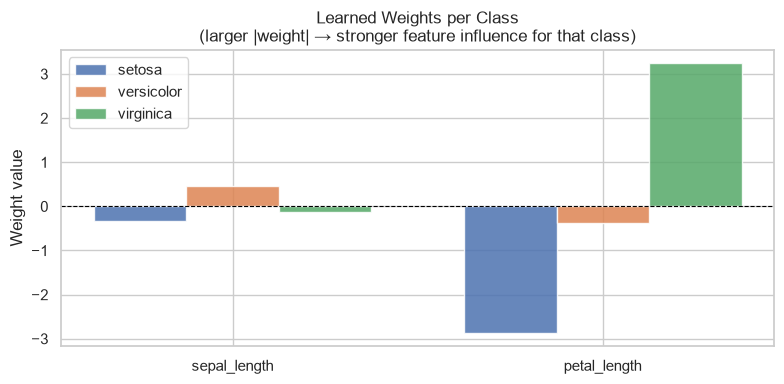

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(feature_names))
width = 0.25
colors = ["#4C72B0", "#DD8452", "#55A868"]
for i, (species, color) in enumerate(zip(softmax_classes, colors)):
    ax.bar(x + i * width, weights.loc[species].values, width, label=species, color=color, alpha=0.85)
ax.set_xticks(x + width)
ax.set_xticklabels(feature_names)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_ylabel("Weight value")
ax.set_title("Learned Weights per Class\n(larger |weight| → stronger feature influence for that class)")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Follow One Prediction Step by Step

For one sample, the complete model calculation is:

1. Calculate the class logits: $\mathbf{z}=W\mathbf{x}+\mathbf{b}$.
2. Convert the logits into probabilities with Softmax:

$$
p_k=\frac{e^{z_k}}{\sum_j e^{z_j}}
$$

3. Select the class with the highest probability: $\hat{y}=\operatorname{argmax}_k p_k$.

The implementation below subtracts the largest logit before exponentiation. This does not change the probabilities and prevents numerical overflow.

**Code notation used in the cell below:**

| Symbol / call | What it means |
|---|---|
| `@` | Matrix multiplication operator — equivalent to `np.dot(A, B)` |
| `.T` | Transpose — flips rows and columns so the shapes align for the multiplication |
| `decision_function(X)` | Sklearn shortcut that computes $W\mathbf{x} + \mathbf{b}$ directly; equivalent to `X @ coef_.T + intercept_` |

In [12]:
def softmax(logits):
    shifted_logits = logits - np.max(logits, axis=1, keepdims=True)
    exponentials = np.exp(shifted_logits)
    return exponentials / np.sum(exponentials, axis=1, keepdims=True)


sample = X_test.iloc[[0]]
logits_manual = sample.to_numpy() @ softmax_model.coef_.T + softmax_model.intercept_
logits_sklearn = softmax_model.decision_function(sample)

probabilities_manual = softmax(logits_manual)
probabilities_sklearn = softmax_model.predict_proba(sample)

calculation = pd.DataFrame(
    {
        "logit_manual": logits_manual[0],
        "logit_sklearn": logits_sklearn[0],
        "probability_manual": probabilities_manual[0],
        "probability_sklearn": probabilities_sklearn[0],
    },
    index=softmax_classes,
)

predicted_position = np.argmax(probabilities_manual, axis=1)
predicted_code = softmax_model.classes_[predicted_position]
predicted_species = encoder.inverse_transform(predicted_code)
actual_species = encoder.inverse_transform(y_test.iloc[[0]].to_numpy())

display(sample)
display(calculation.round(6))
print("Probabilities sum to:", probabilities_manual.sum(axis=1))
print("Manual and scikit-learn logits match:", np.allclose(logits_manual, logits_sklearn))
print("Manual and scikit-learn probabilities match:", np.allclose(probabilities_manual, probabilities_sklearn))
print("Predicted species:", predicted_species[0])
print("Actual species:", actual_species[0])

,sepal_length,petal_length
97,6.2,4.3


,logit_manual,logit_sklearn,probability_manual,probability_sklearn
setosa,-2.373369,-2.373369,0.008688,0.008688
versicolor,2.251414,2.251414,0.885969,0.885969
virginica,0.121955,0.121955,0.105343,0.105343


Probabilities sum to: [1.]
Manual and scikit-learn logits match: True
Manual and scikit-learn probabilities match: True
Predicted species: versicolor
Actual species: versicolor


## 7. Evaluate the Model

**Accuracy** — proportion of all samples predicted correctly:

$$\text{Accuracy} = \frac{\text{Correct predictions}}{N}$$

**Categorical cross-entropy** also penalises low confidence on correct predictions (see Step 4 in the training section).

For each class $k$, where $TP$, $FP$, $FN$ denote true positives, false positives, and false negatives:

**Precision** — of all samples *predicted* as class $k$, how many actually belong to it:

$$\text{Precision}_k = \frac{TP_k}{TP_k + FP_k}$$

**Recall** — of all samples that *actually are* class $k$, how many did the model correctly identify:

$$\text{Recall}_k = \frac{TP_k}{TP_k + FN_k}$$

**F1-score** — harmonic mean of precision and recall; useful when both matter equally:

$$F1_k = 2 \cdot \frac{\text{Precision}_k \times \text{Recall}_k}{\text{Precision}_k + \text{Recall}_k}$$

The **confusion matrix** shows which classes are confused with one another.

In [13]:
y_pred = softmax_model.predict(X_test)
y_probability = softmax_model.predict_proba(X_test)

train_accuracy = accuracy_score(y_train, softmax_model.predict(X_train))
test_accuracy = accuracy_score(y_test, y_pred)
test_cross_entropy = log_loss(y_test, y_probability, labels=softmax_model.classes_)

print(f"Training accuracy: {train_accuracy:.4f}")
print(f"Testing accuracy: {test_accuracy:.4f}")
print(f"Testing categorical cross-entropy: {test_cross_entropy:.4f}\n")

print("Classification report:")
print(classification_report(y_test, y_pred, target_names=softmax_classes))

Training accuracy: 0.9580
Testing accuracy: 0.9667
Testing categorical cross-entropy: 0.1474

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.91      1.00      0.95        10
   virginica       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



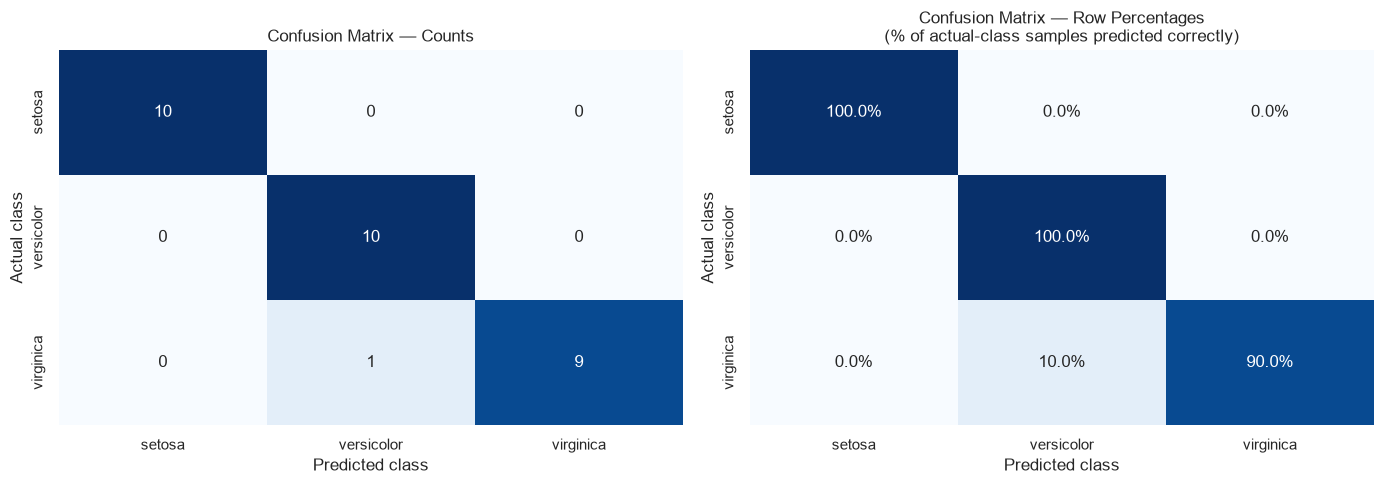

In [14]:
confusion = confusion_matrix(y_test, y_pred, labels=softmax_model.classes_)
confusion_df = pd.DataFrame(
    confusion,
    index=pd.Index(softmax_classes, name="Actual class"),
    columns=pd.Index(softmax_classes, name="Predicted class"),
)
confusion_pct = confusion_df.div(confusion_df.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(confusion_df, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("Confusion Matrix — Counts")

annot_pct = confusion_pct.round(1).astype(str) + "%"
sns.heatmap(confusion_pct, annot=annot_pct, fmt="", cmap="Blues", cbar=False, ax=axes[1])
axes[1].set_title("Confusion Matrix — Row Percentages\n(% of actual-class samples predicted correctly)")
axes[1].set_xlabel("Predicted class")
axes[1].set_ylabel("Actual class")

plt.tight_layout()
plt.show()

### Per-Sample Loss

Beyond accuracy, we can ask: **how confident** was the model on the samples it got right (or wrong)?

Categorical cross-entropy loss for a single sample is:

$$L = -\log(p_{\hat{y}})$$

where $p_{\hat{y}}$ is the probability the model assigned to the **true** class.

| True-class probability | Loss |
|---|---|
| 0.99 (very confident, correct) | 0.01 |
| 0.70 (moderate confidence) | 0.36 |
| 0.50 (uncertain) | 0.69 |
| 0.10 (wrong class favoured) | 2.30 |

A perfect prediction ($p=1$) gives $L=0$. A near-zero probability on the true class gives a very large loss. The cell below computes this for one sample so you can see the number alongside the probability vector.

In [15]:
sample_position = 0
true_class = y_test.iloc[sample_position]
true_class_column = np.where(softmax_model.classes_ == true_class)[0][0]
true_class_probability = y_probability[sample_position, true_class_column]
sample_cross_entropy = -np.log(true_class_probability)

print("True class:", encoder.inverse_transform([true_class])[0])
print(f"Probability assigned to the true class: {true_class_probability:.6f}")
print(f"Per-sample cross-entropy, -log(p_true): {sample_cross_entropy:.6f}")

True class: versicolor
Probability assigned to the true class: 0.885969
Per-sample cross-entropy, -log(p_true): 0.121073


## 8. Visualize the Multiclass Decision Regions

Each colored region contains feature combinations for which one class has the highest Softmax probability. The boundaries occur where two classes receive equal highest scores.

> This plot shows only the two-feature model. A four-feature decision surface cannot be displayed directly on a two-dimensional graph.

/var/folders/36/jp04yqk11pz19cyks4s492tr0000gn/T/ipykernel_9481/2373852671.py:68: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.tight_layout()
/Users/I578366/Desktop/Data Science/Machine-Learning-tutorials/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


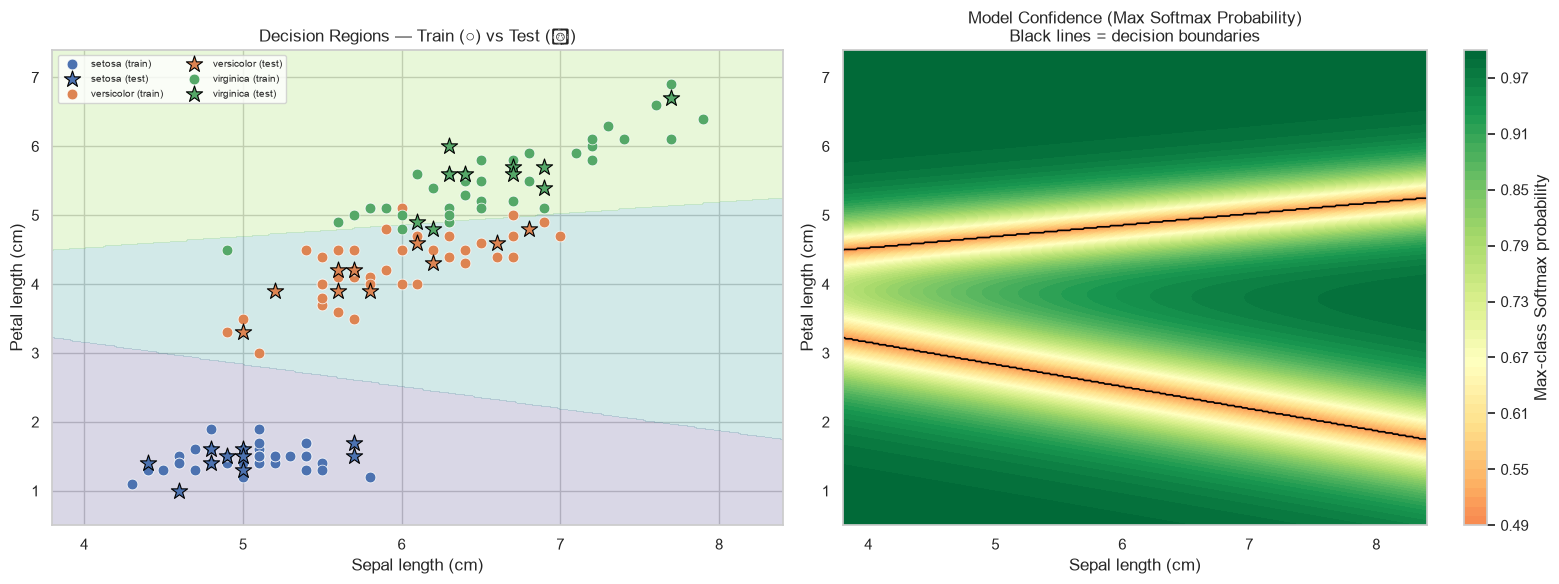

In [16]:
sepal_min, sepal_max = X["sepal_length"].min() - 0.5, X["sepal_length"].max() + 0.5
petal_min, petal_max = X["petal_length"].min() - 0.5, X["petal_length"].max() + 0.5

sepal_grid, petal_grid = np.meshgrid(
    np.linspace(sepal_min, sepal_max, 400),
    np.linspace(petal_min, petal_max, 400),
)
grid = pd.DataFrame(
    {
        "sepal_length": sepal_grid.ravel(),
        "petal_length": petal_grid.ravel(),
    }
)
region_predictions = softmax_model.predict(grid).reshape(sepal_grid.shape)
grid_proba = softmax_model.predict_proba(grid)
max_confidence = grid_proba.max(axis=1).reshape(sepal_grid.shape)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Left: decision regions distinguishing train vs test points ---
ax = axes[0]
ax.contourf(
    sepal_grid, petal_grid, region_predictions,
    alpha=0.20,
    levels=np.arange(len(softmax_classes) + 1) - 0.5,
    cmap="viridis",
)
palette = ["#4C72B0", "#DD8452", "#55A868"]
for class_id, color in zip(softmax_model.classes_, palette):
    species_name = encoder.inverse_transform([class_id])[0]
    mask_tr = y_train == class_id
    mask_te = y_test == class_id
    ax.scatter(
        X_train.loc[mask_tr, "sepal_length"],
        X_train.loc[mask_tr, "petal_length"],
        c=color, marker="o", s=60, edgecolors="white", linewidths=0.5,
        label=f"{species_name} (train)",
    )
    ax.scatter(
        X_test.loc[mask_te, "sepal_length"],
        X_test.loc[mask_te, "petal_length"],
        c=color, marker="*", s=150, edgecolors="black", linewidths=0.8,
        label=f"{species_name} (test)",
    )
ax.set_xlim(sepal_min, sepal_max)
ax.set_ylim(petal_min, petal_max)
ax.set_xlabel("Sepal length (cm)")
ax.set_ylabel("Petal length (cm)")
ax.set_title("Decision Regions — Train (○) vs Test (★)")
ax.legend(fontsize=7.5, ncol=2, loc="upper left")

# --- Right: max-class Softmax probability heatmap ---
ax2 = axes[1]
cf = ax2.contourf(
    sepal_grid, petal_grid, max_confidence,
    levels=50, cmap="RdYlGn", vmin=0.33, vmax=1.0,
)
ax2.contour(
    sepal_grid, petal_grid, region_predictions,
    levels=np.arange(len(softmax_classes) + 1) - 0.5,
    colors="black", linewidths=1.2,
)
plt.colorbar(cf, ax=ax2, label="Max-class Softmax probability")
ax2.set_xlabel("Sepal length (cm)")
ax2.set_ylabel("Petal length (cm)")
ax2.set_title("Model Confidence (Max Softmax Probability)\nBlack lines = decision boundaries")

plt.tight_layout()
plt.show()

## 9. Predict a New Observation

A `DataFrame` makes the feature names and their required order explicit. The probability columns follow `softmax_model.classes_`, so they are labeled with the decoded species names below.

In [17]:
new_flower = pd.DataFrame(
    {
        "sepal_length": [5.8],
        "petal_length": [4.1],
    }
)

new_probabilities = softmax_model.predict_proba(new_flower)
new_encoded_prediction = softmax_model.predict(new_flower)
new_species_prediction = encoder.inverse_transform(new_encoded_prediction)

probability_table = pd.DataFrame(new_probabilities, columns=softmax_classes)
display(new_flower)
display(probability_table.round(6))
print("Predicted encoded class:", new_encoded_prediction[0])
print("Predicted species:", new_species_prediction[0])

,sepal_length,petal_length
0,5.8,4.1


,setosa,versicolor,virginica
0,0.02034,0.912758,0.066902


Predicted encoded class: 1
Predicted species: versicolor


## 10. Compare Models: Features and Scaling

Three configurations are compared to isolate the contribution of each factor:

| Model | Features | Scaling |
|---|---|---|
| Two features (unscaled) | Sepal length + Petal length | None |
| Two features (scaled) | Sepal length + Petal length | StandardScaler |
| All four features (scaled) | All four measurements | StandardScaler |

A scikit-learn `Pipeline` fits `StandardScaler` only on the training data, preventing data leakage during cross-validation. Sections 11, 12, and 13 then examine how L2 regularization strength, training-set size, and cross-validated performance compare across all three configurations.

In [18]:
X_all = raw_df.drop(columns="species")
y_all = raw_df["species"]

X_all_train, X_all_test, y_all_train, y_all_test = train_test_split(
    X_all,
    y_all,
    test_size=0.2,
    random_state=2,
    stratify=y_all,
)

# Wrap the two-feature model in a pipeline for a fair, apples-to-apples comparison
scaled_2feat_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver="lbfgs", max_iter=500),
)
scaled_2feat_model.fit(X_train, y_train)

all_features_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver="lbfgs", max_iter=500),
)
all_features_model.fit(X_all_train, y_all_train)

model_comparison = pd.DataFrame(
    {
        "training_accuracy": [
            train_accuracy,
            scaled_2feat_model.score(X_train, y_train),
            all_features_model.score(X_all_train, y_all_train),
        ],
        "testing_accuracy": [
            test_accuracy,
            scaled_2feat_model.score(X_test, y_test),
            all_features_model.score(X_all_test, y_all_test),
        ],
    },
    index=["Two features (unscaled)", "Two features (scaled)", "All four features (scaled)"],
)

print("Model comparison (single train/test split):")
model_comparison.round(4)

Model comparison (single train/test split):


,training_accuracy,testing_accuracy
Two features (unscaled),0.9580,0.9667
Two features (scaled),0.9412,0.9667
All four features (scaled),0.9580,1.0000


## 11. Regularization Strength (C Parameter Sweep)

`LogisticRegression` always applies L2 regularization. The `C` parameter is the **inverse** of the regularization strength:

- **Small C** (e.g. 0.001) — heavy regularization → weights are pushed toward zero → simpler model → may underfit.
- **Large C** (e.g. 1000) — weak regularization → weights can grow freely → more expressive model → may overfit.

The plot below sweeps `C` across seven decades on a log scale and records the mean 5-fold cross-validated accuracy with its standard deviation. The vertical dashed line marks the scikit-learn default (`C = 1`).

A flat plateau in the middle means the Iris dataset is not sensitive to regularization in this range — useful to confirm the default is reasonable before tuning.

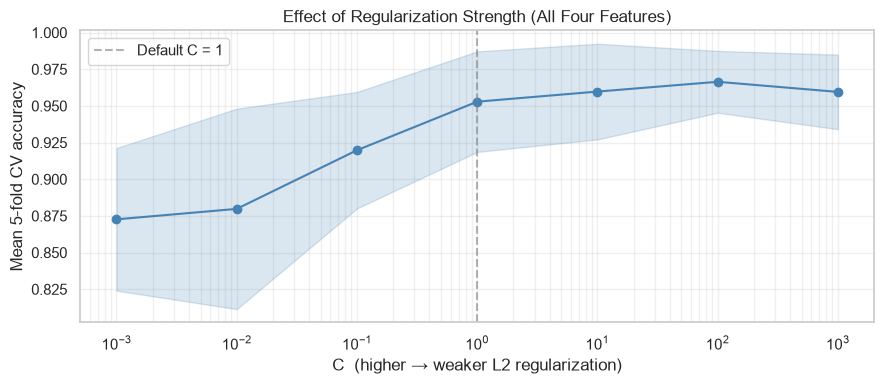

,C,mean_cv_accuracy,std_cv_accuracy
0,0.001,0.8726,0.0486
1,0.010,0.8798,0.0683
2,0.100,0.9198,0.0397
3,1.000,0.9529,0.0343
4,10.000,0.9598,0.0326
5,100.000,0.9664,0.0211
6,1000.000,0.9595,0.0254


In [19]:
from sklearn.model_selection import cross_val_score

C_values = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
cv_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=2)
c_rows = []
for C in C_values:
    m = make_pipeline(
        StandardScaler(),
        LogisticRegression(solver="lbfgs", max_iter=500, C=C),
    )
    cv_acc = cross_val_score(m, X_all, y_all, cv=cv_kfold, scoring="accuracy")
    c_rows.append({"C": C, "mean_cv_accuracy": cv_acc.mean(), "std_cv_accuracy": cv_acc.std()})

c_df = pd.DataFrame(c_rows)

fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogx(c_df["C"], c_df["mean_cv_accuracy"], "o-", color="steelblue")
ax.fill_between(
    c_df["C"],
    c_df["mean_cv_accuracy"] - c_df["std_cv_accuracy"],
    c_df["mean_cv_accuracy"] + c_df["std_cv_accuracy"],
    alpha=0.2, color="steelblue",
)
ax.axvline(x=1.0, color="gray", linestyle="--", alpha=0.6, label="Default C = 1")
ax.set_xlabel("C  (higher → weaker L2 regularization)")
ax.set_ylabel("Mean 5-fold CV accuracy")
ax.set_title("Effect of Regularization Strength (All Four Features)")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()
display(c_df.round(4))

## 12. Learning Curve

A **learning curve** plots model accuracy against training set size. It helps answer: *do we have enough data?*

| Pattern | Diagnosis |
|---|---|
| Training accuracy ≫ CV accuracy across all sizes | Overfitting — more data or stronger regularization needed |
| Both curves low and flat | Underfitting — more expressive model or more features needed |
| Gap closes as size grows | Model benefits from more data |
| Both curves converge high | Good fit — performance is near the dataset ceiling |

The shaded bands show ± one standard deviation across the five cross-validation folds.

/Users/I578366/Desktop/Data Science/Machine-Learning-tutorials/.venv/lib/python3.14/site-packages/sklearn/model_selection/_validation.py:493: FitFailedWarning: 
15 fits failed out of a total of 50.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
15 fits failed with the following error:
Traceback (most recent call last):
  File "/Users/I578366/Desktop/Data Science/Machine-Learning-tutorials/.venv/lib/python3.14/site-packages/sklearn/model_selection/_validation.py", line 860, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/I578366/Desktop/Data Science/Machine-Learning-tutorials/.venv/lib/python3.14/site-packages/sklearn/base.py", line 1403, in wrapper
    

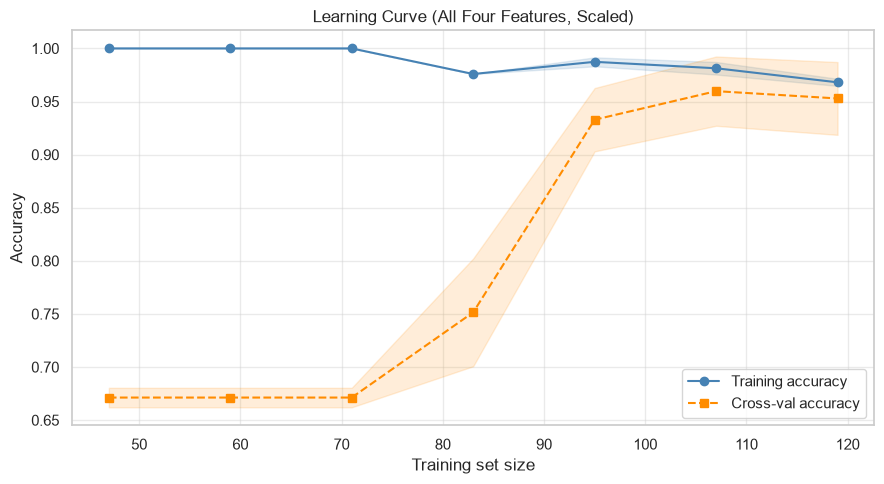

In [20]:
from sklearn.model_selection import learning_curve

train_sizes_abs, train_lc, val_lc = learning_curve(
    make_pipeline(StandardScaler(), LogisticRegression(solver="lbfgs", max_iter=500)),
    X_all, y_all,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=2),
    scoring="accuracy",
    train_sizes=np.linspace(0.1, 1.0, 10),
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(train_sizes_abs, train_lc.mean(axis=1), "o-", color="steelblue", label="Training accuracy")
ax.fill_between(
    train_sizes_abs,
    train_lc.mean(axis=1) - train_lc.std(axis=1),
    train_lc.mean(axis=1) + train_lc.std(axis=1),
    alpha=0.15, color="steelblue",
)
ax.plot(train_sizes_abs, val_lc.mean(axis=1), "s--", color="darkorange", label="Cross-val accuracy")
ax.fill_between(
    train_sizes_abs,
    val_lc.mean(axis=1) - val_lc.std(axis=1),
    val_lc.mean(axis=1) + val_lc.std(axis=1),
    alpha=0.15, color="darkorange",
)
ax.set_xlabel("Training set size")
ax.set_ylabel("Accuracy")
ax.set_title("Learning Curve (All Four Features, Scaled)")
ax.legend()
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

## 13. Cross-Validated Accuracy: Three Configurations

A single train/test split can be misleading for a small dataset like Iris (149 samples). **Stratified K-Fold cross-validation** gives a more reliable estimate:

1. Split the dataset into $K$ equal folds, preserving the class ratio in each fold.
2. For each fold $i$: train on the other $K-1$ folds, evaluate on fold $i$.
3. Average the $K$ accuracy scores.

With $K = 5$ and 149 samples, each fold has ≈ 30 samples (≈ 10 per class). The mean ± std across folds is reported for three configurations so you can compare them fairly — all using `Pipeline` to prevent scaling leakage.

In [21]:
cross_validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=2)

cv_configs = {
    "Two features (unscaled)": (LogisticRegression(solver="lbfgs", max_iter=500), X, y),
    "Two features (scaled)": (
        make_pipeline(StandardScaler(), LogisticRegression(solver="lbfgs", max_iter=500)), X, y
    ),
    "All four features (scaled)": (all_features_model, X_all, y_all),
}

cv_rows = []
for name, (model, X_cv, y_cv) in cv_configs.items():
    results = cross_validate(
        model, X_cv, y_cv, cv=cross_validation,
        scoring={"accuracy": "accuracy", "neg_log_loss": "neg_log_loss"},
    )
    cv_rows.append({
        "model": name,
        "mean_cv_accuracy": results["test_accuracy"].mean(),
        "std_cv_accuracy": results["test_accuracy"].std(),
        "mean_cv_cross_entropy": -results["test_neg_log_loss"].mean(),
    })

cv_summary = pd.DataFrame(cv_rows).set_index("model")
print("Cross-validation model comparison (5-fold):")
display(cv_summary.round(4))

# Fold-by-fold detail for the best model
cv_4feat_results = cross_validate(
    all_features_model, X_all, y_all, cv=cross_validation,
    scoring={"accuracy": "accuracy", "neg_log_loss": "neg_log_loss"},
)
cv_fold_detail = pd.DataFrame({
    "fold": np.arange(1, 6),
    "accuracy": cv_4feat_results["test_accuracy"],
    "categorical_cross_entropy": -cv_4feat_results["test_neg_log_loss"],
})
print("\nFold-by-fold — All four features (scaled):")
display(cv_fold_detail.round(4))
print(f"Mean cross-validation accuracy: {cv_fold_detail['accuracy'].mean():.4f}")
print(
    "Mean cross-validation categorical cross-entropy: "
    f"{cv_fold_detail['categorical_cross_entropy'].mean():.4f}"
)

Cross-validation model comparison (5-fold):


,mean_cv_accuracy,std_cv_accuracy,mean_cv_cross_entropy
model,,,
Two features (unscaled),0.9531,0.0161,0.1830
Two features (scaled),0.9326,0.0306,0.2665
All four features (scaled),0.9529,0.0343,0.1537



Fold-by-fold — All four features (scaled):


,fold,accuracy,categorical_cross_entropy
0,1,0.9000,0.1959
1,2,0.9667,0.1483
2,3,1.0000,0.0836
3,4,0.9667,0.1836
4,5,0.9310,0.1571


Mean cross-validation accuracy: 0.9529
Mean cross-validation categorical cross-entropy: 0.1537


## Key Takeaways

- **Multinomial Logistic Regression** learns one linear score (logit) per class; **Softmax** converts these into probabilities that sum to one.
- `predict()` selects the class with the largest Softmax probability; `predict_proba()` returns the full probability vector.
- **Categorical cross-entropy** penalizes low probability assigned to the true class — it measures both correctness and confidence.
- **Visualizing confidence** alongside decision regions reveals where the model is uncertain near boundaries, not just where it draws lines.
- **Feature scaling matters for fair comparisons**: wrapping every model in a `Pipeline(StandardScaler, LogisticRegression)` isolates the effect of adding features from the effect of scaling.
- **One train/test split can mislead**: 100% test accuracy on 30 samples (10 per class) is plausible by chance. Stratified cross-validation provides a more reliable performance estimate.
- **L2 regularization (C parameter)** trades off bias and variance. A sweep across C values shows whether the default C=1 is near-optimal for a given dataset.
- **Learning curves** reveal whether more data would help: a narrowing gap between training and validation accuracy signals convergence, not just overfitting.
- Feature scaling must be learned from training data only; a scikit-learn `Pipeline` handles this correctly and prevents leakage during cross-validation.